In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Cihaz:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
PyTorch: 2.11.0+cu128
Cihaz: cuda
GPU: NVIDIA L4


In [ ]:
RUN_DIR = "/content/drive/MyDrive/deneme/checkpoints/hnerv384_20260923_131734/"
from pathlib import Path
RUN_DIR = Path(RUN_DIR)

In [ ]:
from pathlib import Path

DATA_ROOT = Path("/content/drive/MyDrive/deneme")
print("Klasör bulundu:", DATA_ROOT.exists())

if DATA_ROOT.exists():
    for path in sorted(DATA_ROOT.iterdir()):
        print(("[Klasör] " if path.is_dir() else "[Dosya]  ") + path.name)

Klasör bulundu: True
[Dosya]  .DS_Store
[Dosya]  384x512Margin01.pt
[Dosya]  384x512Margin02.pt
[Dosya]  384x512Margin03.pt
[Dosya]  384x512Margin04.pt
[Dosya]  384x512Margin05.pt
[Dosya]  384x512Margin06.pt
[Dosya]  384x512Margin07.pt
[Dosya]  384x512Margin08.pt
[Dosya]  384x512Margin09.pt
[Dosya]  384x512Margin10.pt
[Klasör] checkpoints
[Klasör] models
[Klasör] research
[Dosya]  x.py


In [ ]:
from pathlib import Path

VIDEO_PATH = Path("/content/drive/MyDrive/0.mkv")
MODEL_DIR = Path("/content/drive/MyDrive/deneme/models")

for path in (VIDEO_PATH, MODEL_DIR / "posenet.safetensors", MODEL_DIR / "segnet.safetensors"):
    print(f"{'OK' if path.exists() else 'YOK'} | {path}")
    if path.is_file():
        print(f"      Boyut: {path.stat().st_size:,} byte")

assert VIDEO_PATH.exists(), "Video yolu bulunamadı"
assert (MODEL_DIR / "posenet.safetensors").exists(), "PoseNet dosyası bulunamadı"
assert (MODEL_DIR / "segnet.safetensors").exists(), "SegNet dosyası bulunamadı"

OK | /content/drive/MyDrive/0.mkv
      Boyut: 37,545,489 byte
OK | /content/drive/MyDrive/deneme/models/posenet.safetensors
      Boyut: 55,835,560 byte
OK | /content/drive/MyDrive/deneme/models/segnet.safetensors
      Boyut: 38,502,892 byte


In [ ]:
!uv pip -q install av

import av

container = av.open(str(VIDEO_PATH))
stream = container.streams.video[0]
first_frame = next(container.decode(video=0))

print("Video frame boyutu (H, W):", (first_frame.height, first_frame.width))
print("Dosya metadata frame sayısı:", stream.frames)
print("FPS:", float(stream.average_rate))
container.close()

Video frame boyutu (H, W): (874, 1164)
Dosya metadata frame sayısı: 0
FPS: 20.0


In [ ]:
container = av.open(str(VIDEO_PATH))

NUM_FRAMES = sum(1 for _ in container.decode(video=0))
container.close()

NUM_PAIRS = (NUM_FRAMES + 1) // 2

print("Gerçek frame sayısı:", NUM_FRAMES)
print("İşlenecek frame pair sayısı:", NUM_PAIRS)
print("Tek frame varsa son frame kopyalanacak:", NUM_FRAMES % 2 == 1)

Gerçek frame sayısı: 1200
İşlenecek frame pair sayısı: 600
Tek frame varsa son frame kopyalanacak: False


In [ ]:
!uv pip -q install segmentation-models-pytorch timm einops safetensors

In [ ]:
import sys
import torch
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_DIR = Path("/content/drive/MyDrive/deneme/models")
sys.path.insert(0, "/content/drive/MyDrive/deneme")

from research.modules import DistortionNet

distortion_net = DistortionNet().eval().to(device)
distortion_net.load_state_dicts(
    MODEL_DIR / "posenet.safetensors",
    MODEL_DIR / "segnet.safetensors",
    device,
)
distortion_net.requires_grad_(False)

print("Evaluator yüklendi:", device)

Evaluator yüklendi: cuda


In [ ]:
from research.oracle_pair import (
    load_pair,
    pose_preprocess_grad,
    seg_preprocess_grad,
)

VIDEO_PATH = Path("/content/drive/MyDrive/0.mkv")

pair = load_pair(VIDEO_PATH, start_frame=0).to(device)

with torch.inference_mode():
    pose_input = pose_preprocess_grad(pair)
    seg_input = seg_preprocess_grad(pair)
    pose_output = distortion_net.posenet(pose_input)["pose"][..., :6]
    seg_output = distortion_net.segnet(seg_input)

print("Kaynak pair:", tuple(pair.shape))
print("PoseNet girişi:", tuple(pose_input.shape))
print("SegNet girişi:", tuple(seg_input.shape))
print("Çıktılar:", tuple(pose_output.shape), tuple(seg_output.shape))

Kaynak pair: (1, 2, 3, 874, 1164)
PoseNet girişi: (1, 12, 192, 256)
SegNet girişi: (1, 3, 384, 512)
Çıktılar: (1, 6) (1, 5, 384, 512)


In [ ]:
import torch.nn.functional as F

with torch.inference_mode():
    # Orijinal ilk pair'in evaluator hedefleri
    target_pose = distortion_net.posenet(
        pose_preprocess_grad(pair)
    )["pose"][..., :6]

    target_seg = distortion_net.segnet(
        seg_preprocess_grad(pair)
    ).argmax(dim=1)

    # Basit native 384x512 temsil → gerçek HNeRV inflate adımı
    native = F.interpolate(
        pair.reshape(2, 3, 874, 1164),
        size=(384, 512),
        mode="bilinear",
        align_corners=False,
    )
    inflated = F.interpolate(
        native,
        size=(874, 1164),
        mode="bicubic",
        align_corners=False,
    ).clamp(0, 255).round()

    candidate = inflated.reshape(1, 2, 3, 874, 1164)

    candidate_pose = distortion_net.posenet(
        pose_preprocess_grad(candidate)
    )["pose"][..., :6]

    candidate_seg = distortion_net.segnet(
        seg_preprocess_grad(candidate)
    ).argmax(dim=1)

    pose_dist = torch.nn.functional.mse_loss(candidate_pose, target_pose).item()
    seg_dist = (candidate_seg != target_seg).float().mean().item()
    score = 100 * seg_dist + (10 * pose_dist) ** 0.5

print(f"İlk pair round-trip | Pose={pose_dist:.8f} Seg={seg_dist:.8f} Score={score:.8f}")
print("Kontrol şekli:", tuple(candidate.shape))

İlk pair round-trip | Pose=0.00025792 Seg=0.00015259 Score=0.06604435
Kontrol şekli: (1, 2, 3, 874, 1164)


In [ ]:
import torch
import torch.nn.functional as F

def inflate_for_training(native):
    b, t, c, h, w = native.shape
    assert (t, c, h, w) == (2, 3, 384, 512), native.shape

    flat = native.reshape(b * 2, 3, h, w)
    up = F.interpolate(
        flat,
        size=(874, 1164),
        mode="bicubic",
        align_corners=False,
    )
    up = up.clamp(0, 255)

    # İleri geçişte gerçek çözücü gibi yuvarlar;
    # geri yayılımda gradyanın geçmesine izin verir.
    rounded = up + (up.round() - up).detach()
    return rounded.reshape(b, 2, 3, 874, 1164)

In [ ]:
BATCH_PAIRS = 4
pose_sum = 0.0
seg_sum = 0.0
pair_count = 0
pair_buffer = []
frame_buffer = []

def measure_batch(cpu_pairs):
    global pose_sum, seg_sum, pair_count

    gt = torch.stack(cpu_pairs).to(device)  # (B, 2, 3, 874, 1164)
    b = gt.shape[0]

    with torch.inference_mode():
        target_pose = distortion_net.posenet(
            pose_preprocess_grad(gt)
        )["pose"][..., :6]
        target_seg = distortion_net.segnet(
            seg_preprocess_grad(gt)
        ).argmax(dim=1)

        native = F.interpolate(
            gt.reshape(b * 2, 3, 874, 1164),
            size=(384, 512),
            mode="bilinear",
            align_corners=False,
        )
        camera = F.interpolate(
            native,
            size=(874, 1164),
            mode="bicubic",
            align_corners=False,
        ).clamp(0, 255).round()
        candidate = camera.reshape(b, 2, 3, 874, 1164)

        pred_pose = distortion_net.posenet(
            pose_preprocess_grad(candidate)
        )["pose"][..., :6]
        pred_seg = distortion_net.segnet(
            seg_preprocess_grad(candidate)
        ).argmax(dim=1)

        pose_sum += (pred_pose - target_pose).square().mean(dim=1).sum().item()
        seg_sum += (pred_seg != target_seg).float().mean(dim=(1, 2)).sum().item()
        pair_count += b

container = av.open(str(VIDEO_PATH))

for frame in container.decode(video=0):
    rgb = torch.from_numpy(
        frame.to_ndarray(format="rgb24")
    ).permute(2, 0, 1).float()
    frame_buffer.append(rgb)

    if len(frame_buffer) == 2:
        pair_buffer.append(torch.stack(frame_buffer))
        frame_buffer = []

    if len(pair_buffer) == BATCH_PAIRS:
        measure_batch(pair_buffer)
        pair_buffer = []
        if pair_count % 100 == 0:
            print(f"Ölçüldü: {pair_count}/{NUM_PAIRS}")

container.close()

if pair_buffer:
    measure_batch(pair_buffer)

pose_dist = pose_sum / pair_count
seg_dist = seg_sum / pair_count
score = 100 * seg_dist + (10 * pose_dist) ** 0.5

print(f"Tüm video round-trip | Pose={pose_dist:.8f} Seg={seg_dist:.8f} Score={score:.8f}")
print("Pair sayısı:", pair_count)

Ölçüldü: 100/600
Ölçüldü: 200/600
Ölçüldü: 300/600
Ölçüldü: 400/600
Ölçüldü: 500/600
Ölçüldü: 600/600
Tüm video round-trip | Pose=0.00021294 Seg=0.00019259 Score=0.06540436
Pair sayısı: 600


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class HNeRVDecoder(nn.Module):
    def __init__(self, latent_dim=28, base_channels=36):
        super().__init__()
        self.alpha = 0.0
        self.base_h, self.base_w = 6, 8
        c = base_channels
        self.channels = [c, c, c, int(c * 0.75), int(c * 0.58), int(c * 0.5), int(c * 0.5)]

        self.stem = nn.Linear(latent_dim, self.channels[0] * 6 * 8)
        self.blocks = nn.ModuleList()
        self.skips = nn.ModuleList()

        for i in range(6):
            in_ch, out_ch = self.channels[i], self.channels[i + 1]
            self.blocks.append(nn.Conv2d(in_ch, out_ch * 4, 3, padding=1))
            self.skips.append(nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity())

        self.ps = nn.PixelShuffle(2)
        final_ch = self.channels[-1]
        self.refine = nn.Sequential(
            nn.Conv2d(final_ch, final_ch // 2, 3, padding=2, dilation=2),
            nn.Conv2d(final_ch // 2, final_ch, 3, padding=1),
        )
        self.rgb_0 = nn.Conv2d(final_ch, 3, 3, padding=1)
        self.rgb_1 = nn.Conv2d(final_ch, 3, 3, padding=1)

    def forward(self, z):
        b = z.shape[0]
        a = self.alpha

        h = self.stem(z).view(b, self.channels[0], 6, 8)
        x = (1.0 - a) * torch.sin(h) + a * F.gelu(h)

        for block, skip in zip(self.blocks, self.skips):
            identity = F.interpolate(
                x, scale_factor=2, mode="bilinear", align_corners=False
            )
            h = self.ps(block(x)) + skip(identity)
            x = (1.0 - a) * torch.sin(h) + a * F.gelu(h)

        h = self.refine(x)
        x = x + 0.1 * (
            (1.0 - a) * torch.sin(h) + a * F.gelu(h)
        )

        f0 = torch.sigmoid(self.rgb_0(x)) * 255.0
        f1 = torch.sigmoid(self.rgb_1(x)) * 255.0
        return torch.stack([f0, f1], dim=1)

decoder = HNeRVDecoder().to(device)
latents = nn.Parameter(torch.zeros(NUM_PAIRS, 28, device=device))

with torch.inference_mode():
    test_output = decoder(latents[:2])

print("İki pair çıktısı:", tuple(test_output.shape))
print("Decoder parametresi:", sum(p.numel() for p in decoder.parameters()))
print("Latent parametresi:", latents.numel())

İki pair çıktısı: (2, 2, 3, 384, 512)
Decoder parametresi: 228958
Latent parametresi: 16800


In [ ]:
from research.frame_utils import yuv420_to_rgb

container = av.open(str(VIDEO_PATH))
frame = next(container.decode(video=0))

rgb_pyav = torch.from_numpy(frame.to_ndarray(format="rgb24"))
rgb_evaluator = yuv420_to_rgb(frame)
container.close()

diff = (rgb_pyav.to(torch.int16) - rgb_evaluator.to(torch.int16)).abs()

print("Frame formatı:", frame.format.name)
print("İki RGB dönüşümü arasındaki ortalama fark:", diff.float().mean().item())
print("Maksimum fark:", diff.max().item())
print("Farklı piksel kanalı oranı:", (diff > 0).float().mean().item())

Frame formatı: yuv420p
İki RGB dönüşümü arasındaki ortalama fark: 2.0579798221588135
Maksimum fark: 50
Farklı piksel kanalı oranı: 0.8175276517868042


In [ ]:
from pathlib import Path
import torch

TARGET_CACHE = Path(
    "/content/drive/MyDrive/deneme/checkpoints/"
    "hnerv384_targets_evalrgb_v1.pt"
)
assert TARGET_CACHE.is_file(), TARGET_CACHE

targets = torch.load(TARGET_CACHE, map_location="cpu", weights_only=True)

seg_targets_gpu = targets["seg_class"].to(device, dtype=torch.uint8)
pose_targets_gpu = targets["pose"].to(device, dtype=torch.float32)

print("Seg:", seg_targets_gpu.shape, seg_targets_gpu.dtype)
print("Pose:", pose_targets_gpu.shape, pose_targets_gpu.dtype)

Seg: torch.Size([600, 384, 512]) torch.uint8
Pose: torch.Size([600, 6]) torch.float32


In [ ]:
@torch.inference_mode()
def measure_decoder(eval_batch_size=8):
    pose_sum = 0.0
    seg_sum = 0.0
    pair_count = 0

    # Ölçüm bitince önceki train/eval durumlarını geri yükle.
    flags = [
        (module, module.training)
        for root in (decoder, distortion_net)
        for module in root.modules()
    ]

    old_mm = torch.backends.cuda.matmul.allow_tf32
    old_cudnn = torch.backends.cudnn.allow_tf32

    decoder.eval()
    distortion_net.eval()

    # Audit fonksiyonuyla aynı sayısal ayarlar.
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

    try:
        with torch.autocast(
            device_type=torch.device(device).type,
            enabled=False,
        ):
            for start in range(0, NUM_PAIRS, eval_batch_size):
                ids = torch.arange(
                    start,
                    min(start + eval_batch_size, NUM_PAIRS),
                    device=device,
                )

                # Gerçek görüntüyü küçültmek yerine modelden üret.
                native = decoder(latents[ids])

                # Bicubic büyütme + clamp + ileri geçişte yuvarlama.
                candidate = inflate_for_training(native)

                pred_pose = distortion_net.posenet(
                    pose_preprocess_grad(candidate).contiguous(
                        memory_format=torch.channels_last
                    )
                )["pose"][:, :6].float()

                pred_seg = distortion_net.segnet(
                    seg_preprocess_grad(candidate).contiguous(
                        memory_format=torch.channels_last
                    )
                ).argmax(dim=1)

                target_pose = pose_targets_gpu[ids].float()
                target_seg = seg_targets_gpu[ids].long()

                # Önce pair başına hata, ardından bütün pair'lerde toplam.
                pose_error = (
                    pred_pose - target_pose
                ).square().double().mean(dim=1)

                seg_error = (
                    pred_seg != target_seg
                ).double().mean(dim=(1, 2))

                pose_sum += pose_error.sum().item()
                seg_sum += seg_error.sum().item()
                pair_count += len(ids)

                del native, candidate, pred_pose, pred_seg
                del target_pose, target_seg, pose_error, seg_error

        pose_dist = pose_sum / pair_count
        seg_dist = seg_sum / pair_count

        # Karekök, bütün pair'lerin Pose MSE ortalamasından sonra.
        score = 100 * seg_dist + (10 * pose_dist) ** 0.5

        return pose_dist, seg_dist, score

    finally:
        torch.backends.cuda.matmul.allow_tf32 = old_mm
        torch.backends.cudnn.allow_tf32 = old_cudnn

        for module, training in flags:
            module.training = training

# **OLDSHIII**

In [ ]:
latest_path = RUN_DIR / f"class1w1p5_epoch{best_epoch}.pt"
reference_best = float("inf")  # kontrol kolunun en iyisini ayrı kaydet

latest = torch.load(
    RUN_DIR / f"class1w1p5_epoch{best_epoch}.pt",
    map_location="cpu",
    weights_only=True,
)

for epochs in [
    (umm+7, umm+8, umm+9),
    tuple(range(umm+4, umm+10)),
    tuple(range(umm, umm+10)),
    tuple(range(umm-10, umm+10)),
    tuple(range(umm-20, umm+10)),

]:
    states = [
        torch.load(
            RUN_DIR / f"class1w1p5_epoch{e}.pt",
            map_location="cpu",
            weights_only=True,
        )
        for e in epochs
    ]

    avg_decoder = {
        key: torch.stack([s["decoder"][key].float() for s in states]).mean(0)
        for key in states[0]["decoder"]
    }
    avg_latents = torch.stack(
        [s["latents"].float() for s in states]
    ).mean(0)

    decoder.load_state_dict(avg_decoder)
    with torch.no_grad():
        latents.copy_(avg_latents.to(device))

    pose_d, seg_d, score, class1_err = measure_decoder()
    print(
        f"Ortalama {epochs} | Pose={pose_d:.6f} Seg={seg_d:.6f} "
        f"Score={score:.6f} class1_hata={class1_err:.1f}%"
    )

    if score < reference_best:
        reference_best = score
        torch.save(
            {
                "decoder": avg_decoder,
                "latents": avg_latents,
                "source_epochs": epochs,
                "distortion_score": score,
            },
            RUN_DIR / f"averaged_{epochs[0]}_{epochs[-1]}.pt",
        )

# Eğitime devam edebilmek için epoch 39 ve mevcut optimizer'ı hizalı bırak.
decoder.load_state_dict(latest["decoder"])
with torch.no_grad():
    latents.copy_(latest["latents"].to(device))



In [ ]:
epochs = tuple(range(270, 300))
output_path = RUN_DIR / "averaged_class1w1p5_270_299.pt"

latest = torch.load(
    RUN_DIR / f"class1w1p5_epoch{best_epoch}.pt",
    map_location="cpu",
    weights_only=True,
)
states = [
    torch.load(
        RUN_DIR / f"class1w1p5_epoch{e}.pt",
        map_location="cpu",
        weights_only=True,
    )
    for e in epochs
]

avg_decoder = {
    key: torch.stack(
        [s["decoder"][key].float() for s in states]
    ).mean(0)
    for key in states[0]["decoder"]
}
avg_latents = torch.stack(
    [s["latents"].float() for s in states]
).mean(0)

was_training = decoder.training

try:
    decoder.load_state_dict(avg_decoder)
    with torch.no_grad():
        latents.copy_(avg_latents.to(device))

    pose_d, seg_d, score, class1_err = measure_decoder()
    print(
        f"Kontrol | Pose={pose_d:.6f} Seg={seg_d:.6f} "
        f"Score={score:.6f} class1_hata={class1_err:.1f}%"
    )
    assert abs(score - 0.330502) < 0.002
    torch.save(
        {
            "decoder": avg_decoder,
            "latents": avg_latents,
            "source_epochs": epochs,
            "distortion_score": score,
        },
        output_path,
    )
    print("Kaydedildi:", output_path)
    print("Dosya var mı?", output_path.exists())

finally:
    decoder.load_state_dict(latest["decoder"])
    with torch.no_grad():
        latents.copy_(latest["latents"].to(device))
    optimizer.load_state_dict(latest["optimizer"])
    decoder.train(was_training)
    print("Epoch 159 model + optimizer geri yüklendi.")

In [ ]:
import lzma
from pathlib import Path

candidates = []
for p in RUN_DIR.glob("averaged_class1w1p5_270_299.pt"):
    if "_fp16" in p.stem:
        continue
    ck = torch.load(p, map_location="cpu", weights_only=True)
    if "distortion_score" in ck:
        candidates.append((float(ck["distortion_score"]), p))

assert candidates, "Kayıtlı ortalama model bulunamadı."
best_score, best_path = min(candidates, key=lambda item: item[0])
assert abs(best_score - 0.330502) < 0.002, (best_score, best_path)
print("Seçilen model:", best_path.name, "| skor:", best_score)

best = torch.load(best_path, map_location="cpu", weights_only=True)
half_decoder = {
    k: v.half() if v.is_floating_point() else v
    for k, v in best["decoder"].items()
}
half_latents = best["latents"].half()

saved_decoder = {
    k: v.detach().clone()
    for k, v in decoder.state_dict().items()
}
saved_latents = latents.detach().clone()
was_training = decoder.training

fp16_path = best_path.with_name(best_path.stem + "_fp16.pt")
xz_path = best_path.with_name(best_path.stem + "_fp16.pt.xz")
video_path = Path("/content/drive/MyDrive/0.mkv")

try:
    decoder.load_state_dict(half_decoder)
    with torch.no_grad():
        latents.copy_(half_latents.to(device))

    pose_d, seg_d, score, class1_err = measure_decoder()

    torch.save(
        {
            "decoder": half_decoder,
            "latents": half_latents,
            "source_epochs": best["source_epochs"],
            "distortion_score": score,
            "format": "fp16",
        },
        fp16_path,
    )

    with lzma.open(xz_path, "wb", preset=9) as f:
        f.write(fp16_path.read_bytes())

    rate = xz_path.stat().st_size / video_path.stat().st_size
    print(f"FP16 | Pose={pose_d:.8f} Seg={seg_d:.8f} Distortion={score:.8f}")
    print(f"XZ dosyası={xz_path.stat().st_size / 1e6:.3f} MB")
    print(f"Kaba rate={rate:.8f} | kaba toplam={score + 25 * rate:.8f}")

finally:
    decoder.load_state_dict(saved_decoder)
    with torch.no_grad():
        latents.copy_(saved_latents)
    decoder.train(was_training)
    print("Önceki model durumu geri yüklendi.")

# **Train Loop**

In [ ]:
from pathlib import Path
import importlib.util
import urllib.request

CODEC_PATH = Path("/content/hnerv_codec.py")
CODEC_URL = (
    "https://raw.githubusercontent.com/commaai/"
    "comma_video_compression_challenge/"
    "20fbc0d3c4dfc1262fc3a3509e7d69d77fefadc2/"
    "submissions/hnerv_muon/src/codec.py"
)

if not CODEC_PATH.exists():
    urllib.request.urlretrieve(CODEC_URL, CODEC_PATH)

spec = importlib.util.spec_from_file_location("hnerv_codec", CODEC_PATH)
hnerv_codec = importlib.util.module_from_spec(spec)
spec.loader.exec_module(hnerv_codec)

In [ ]:
import csv, io, json, math, time, zipfile
from pathlib import Path
from datetime import datetime

import torch
import torch.nn.functional as F

TARGET_ALPHA5 = 0.01

EPOCHS5 = 6
BATCH5 = 20
STEPS_PER_EPOCH5 = 75
SAMPLES_PER_EPOCH5 = BATCH5 * STEPS_PER_EPOCH5

LR_DECODER5 = 2e-5
LR_LATENTS5 = 2e-4
WEIGHT_DECAY5 = 0.0

K_FRAC5 = 0.15
TARGET_ALPHA5 = 0.0   # alpha denemesi kazanç vermedi, kaynağın değeri
EPOCHS5 = 10          # yeni kapasitenin öğrenmesi zaman alır
PATIENCE5 = 4
CLASS1_BAND3_BOOST5 = 2.0
BOUNDARY01_WEIGHT5 = 0.30

EMA_DECAY5 = 0.99
SCHED_PATIENCE5 = 1      # 1 epoch iyileşme yoksa LR yarıya
PATIENCE5 = 3            # 3 epoch iyileşme yoksa dur

EVAL_BATCH5 = 8
PRINT_TOP5 = 5
SAVE_MAPS5 = True
MAP_TOP5 = 3
DISPLAY_MAPS5 = False    # her epoch'ta resim basmasın

RATE_WEIGHT5 = 25
VIDEO_BYTES5 = VIDEO_PATH.stat().st_size          # rate paydası: orijinal video
META5 = {"n_pairs": 600, "latent_dim": 28, "base_channels": 36, "eval_size": [384, 512]}

FRAME_IDS5 = torch.arange(NUM_PAIRS * 2).reshape(NUM_PAIRS, 2)

source_path5 = Path(
    "/content/drive/MyDrive/deneme/checkpoints/"
    "hnerv384_20260923_131734/"
    "boundary_latent_pilot_20260927_115752/"
    "warmrestart_ema_20260927_133748/"
    "warmrestart_ema_20260927_141559/"
    "warmrestart_ema_20260927_182103/"
    "warmrestart_ema_20260927_192528/"
    "warmrestart_ema_20260927_195852/"
    "warmrestart_ema_20260927_203157/"
    "warmrestart_ema_20260927_210510/"
    "warmrestart_ema_20260927_213833/"
    "warmrestart_ema_20260928_054012/"
    "warmrestart_ema_20260928_061706/"
    "warmrestart_ema_20260928_071249/"
    "warmrestart_ema_20260928_081405/"
    "warmrestart_ema_20260928_105108/"
    "warmrestart_ema_20260928_125550/"
    "warmrestart_ema_20260928_131745/"
    "warmrestart_ema_20260928_135439/"
    "warmrestart_ema_20260929_075138/"
    "warmrestart_ema_20260929_101516/"
    "warmrestart_ema_20260929_104037/"
    "warmrestart_ema_20260929_104037/"
    #"v6_fp32_alpha_0.0000_20260930_092511/"
    "best.pt"
)


assert hasattr(decoder, "alpha")
assert NUM_PAIRS == 600 and latents.dtype == torch.float32
assert latents.shape[0] == seg_targets_gpu.shape[0] == pose_targets_gpu.shape[0] == NUM_PAIRS
assert "hnerv_codec" in globals(), "Önce cell 24'teki codec yükleme kısmını çalıştır"
assert source_path5.is_file(), source_path5
print("Video byte:", f"{VIDEO_BYTES5:,}")

AssertionError: /content/drive/MyDrive/deneme/checkpoints/hnerv384_20260923_131734/boundary_latent_pilot_20260927_115752/warmrestart_ema_20260927_133748/warmrestart_ema_20260927_141559/warmrestart_ema_20260927_182103/warmrestart_ema_20260927_192528/warmrestart_ema_20260927_195852/warmrestart_ema_20260927_203157/warmrestart_ema_20260927_210510/warmrestart_ema_20260927_213833/warmrestart_ema_20260928_054012/warmrestart_ema_20260928_061706/warmrestart_ema_20260928_071249/warmrestart_ema_20260928_081405/warmrestart_ema_20260928_105108/warmrestart_ema_20260928_125550/warmrestart_ema_20260928_131745/warmrestart_ema_20260928_135439/warmrestart_ema_20260929_075138/warmrestart_ema_20260929_101516/warmrestart_ema_20260929_104037/warmrestart_ema_20260929_104037/best.pt

In [ ]:
import os
os.listdir(source_path5)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/deneme/checkpoints/hnerv384_20260923_131734/boundary_latent_pilot_20260927_115752/warmrestart_ema_20260927_133748/warmrestart_ema_20260927_141559/warmrestart_ema_20260927_182103/warmrestart_ema_20260927_192528/warmrestart_ema_20260927_195852/warmrestart_ema_20260927_203157/warmrestart_ema_20260927_210510/warmrestart_ema_20260927_213833/warmrestart_ema_20260928_054012/warmrestart_ema_20260928_061706/warmrestart_ema_20260928_071249/warmrestart_ema_20260928_081405/warmrestart_ema_20260928_105108/warmrestart_ema_20260928_125550/warmrestart_ema_20260928_131745/warmrestart_ema_20260928_135439/warmrestart_ema_20260929_075138/warmrestart_ema_20260929_101516/warmrestart_ema_20260929_104037/warmrestart_ema_20260929_104037/best.pt'

In [ ]:
print(best_path5)

In [ ]:
# Sinüs–GELU karışımlı forward kullanan decoder ile çalıştır.
# Mevcut decoder, latents, target ve preprocessing hücrelerinden SONRA çalıştır.
# Önceki continuation hücresinin YERİNE kullan.
# TARGET_ALPHA5 bütün pilot boyunca sabit kalır.
# Kaynak checkpoint değiştirilmez; sonuçlar yeni klasöre kaydedilir.

import csv
import json
import math
import time
from pathlib import Path
from datetime import datetime

import torch
import torch.nn.functional as F


# ------------------------------------------------------------------
# AUDIT
# ------------------------------------------------------------------

def interface_bands5(truth):
    is0, is1 = truth == 0, truth == 1

    near1 = F.max_pool2d(
        is1.float().unsqueeze(1), 3, 1, 1
    )[:, 0] > 0
    near0 = F.max_pool2d(
        is0.float().unsqueeze(1), 3, 1, 1
    )[:, 0] > 0

    interface = (is0 & near1) | (is1 & near0)

    near3 = F.max_pool2d(
        interface.float().unsqueeze(1), 7, 1, 3
    )[:, 0] > 0
    near6 = F.max_pool2d(
        interface.float().unsqueeze(1), 13, 1, 6
    )[:, 0] > 0

    return near3, near6 & ~near3, ~near6


def summarize_audit5(pair_confusion, pose_sq, band_confusion, frame_ids):
    conf = pair_confusion.sum(0)
    support = conf.sum(1)
    wrong = support - conf.diag()
    false_positive = conf.sum(0) - conf.diag()

    pixels_per_pair = pair_confusion.sum((1, 2))
    pair_wrong = (
        pixels_per_pair
        - pair_confusion.diagonal(dim1=1, dim2=2).sum(1)
    )
    pair_seg = pair_wrong.double() / pixels_per_pair
    pair_pose = pose_sq.double().mean(1)

    n = len(pair_seg)
    seg = float(pair_seg.mean())
    pose = float(pair_pose.mean())

    seg_score = 100 * seg
    pose_score = math.sqrt(10 * pose)

    # Yalnız bu pair'in hataları sıfır olsaydı teorik skor kazancı.
    oracle_gain = (
        100 * pair_seg / n
        + pose_score
        - (10 * (pose - pair_pose / n).clamp_min(0)).sqrt()
    )

    total_pixels = int(conf.sum())
    total_wrong = int(wrong.sum())

    classes = []
    for c in range(len(conf)):
        count = int(support[c])
        err = int(wrong[c])

        classes.append({
            "class_id": c,
            "support": count,
            "wrong": err,
            "error_pct": 100 * err / count if count else None,
            "false_positive": int(false_positive[c]),
            "share_of_all_errors_pct": (
                100 * err / total_wrong if total_wrong else 0.0
            ),
            "seg_score_contribution": 100 * err / total_pixels,
        })

    bands = []
    for name, cm in zip(("0-3px", "4-6px", ">6px"), band_confusion):
        count = int(cm.sum())
        err = count - int(cm.diag().sum())
        d0 = int(cm[0].sum())
        d1 = int(cm[1].sum())

        bands.append({
            "band": name,
            "pixels": count,
            "wrong_all_classes": err,
            "error_pct": 100 * err / count if count else None,
            "share_of_all_errors_pct": (
                100 * err / total_wrong if total_wrong else 0.0
            ),
            "n01": int(cm[0, 1]),
            "n10": int(cm[1, 0]),
            "share_of_all_01_pct": (
                100 * int(cm[0, 1]) / int(conf[0, 1])
                if int(conf[0, 1]) else 0.0
            ),
            "share_of_all_10_pct": (
                100 * int(cm[1, 0]) / int(conf[1, 0])
                if int(conf[1, 0]) else 0.0
            ),
            "class0_support": d0,
            "class1_support": d1,
            "rate01_pct": 100 * int(cm[0, 1]) / d0 if d0 else None,
            "rate10_pct": 100 * int(cm[1, 0]) / d1 if d1 else None,
        })

    pairs = []
    for i in range(n):
        cm = pair_confusion[i]
        bad = cm.clone()
        bad.fill_diagonal_(0)
        dominant = int(bad.argmax())

        row = {
            "pair_id": i,
            "frame0": int(frame_ids[i, 0]),
            "frame1": int(frame_ids[i, 1]),
            "seg_frame": int(frame_ids[i, 1]),
            "wrong_pixels": int(pair_wrong[i]),
            "seg_error_pct": 100 * float(pair_seg[i]),
            "seg_dist": float(pair_seg[i]),
            "pose_mse": float(pair_pose[i]),
            "n01": int(cm[0, 1]),
            "n10": int(cm[1, 0]),
            "dominant_confusion": (
                f"{dominant // len(conf)}->{dominant % len(conf)}"
                if int(bad.sum()) else "none"
            ),
            "oracle_gain_if_pair_perfect": float(oracle_gain[i]),
        }

        for c in range(len(conf)):
            row[f"class{c}_support"] = int(cm[c].sum())
            row[f"class{c}_wrong"] = int(cm[c].sum() - cm[c, c])

        for d in range(pose_sq.shape[1]):
            row[f"pose_dim{d}_squared_error"] = float(pose_sq[i, d])

        pairs.append(row)

    return {
        "pose_dist": pose,
        "seg_dist": seg,
        "distortion_score": seg_score + pose_score,
        "seg_score_term": seg_score,
        "pose_score_term": pose_score,
        "total_wrong": total_wrong,
        "total_pixels": total_pixels,
        "confusion": conf.tolist(),
        "classes": classes,
        "bands": bands,
        "pairs": pairs,
        "pose_dimension_mse": pose_sq.double().mean(0).tolist(),
        "metric": (
            "100*mean_pair_seg_disagreement + "
            "sqrt(10*mean_pair_pose_mse); RATE EXCLUDED"
        ),
        "frame_id_convention": (
            "zero-based; supplied frame_ids mapping; "
            "SegNet uses pair's last frame"
        ),
    }


@torch.inference_mode()
def audit_decoder5(eval_batch_size=None):
    batch_size = (
        EVAL_BATCH5 if eval_batch_size is None else eval_batch_size
    )

    flags = [
        (m, m.training)
        for root in (decoder, distortion_net)
        for m in root.modules()
    ]
    old_mm = torch.backends.cuda.matmul.allow_tf32
    old_cudnn = torch.backends.cudnn.allow_tf32

    decoder.eval()
    distortion_net.eval()
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

    pair_cms = []
    pose_errors = []
    total_bands = None
    gallery = []

    try:
        with torch.autocast(
            device_type=torch.device(device).type,
            enabled=False,
        ):
            for start in range(0, NUM_PAIRS, batch_size):
                ids = torch.arange(
                    start,
                    min(start + batch_size, NUM_PAIRS),
                    device=device,
                )

                full = inflate_for_training(decoder(latents[ids]))
                seg_input = seg_preprocess_grad(full).contiguous(
                    memory_format=torch.channels_last
                )

                logits = distortion_net.segnet(seg_input).float()
                pred = logits.argmax(1)
                truth = seg_targets_gpu[ids].long()
                c = logits.shape[1]

                assert truth.shape == pred.shape and c >= 2
                assert bool(((truth >= 0) & (truth < c)).all()), (
                    "Unsupported target/ignore label"
                )

                pose = distortion_net.posenet(
                    pose_preprocess_grad(full).contiguous(
                        memory_format=torch.channels_last
                    )
                )["pose"][:, :6].float()

                sq = (pose - pose_targets_gpu[ids].float()).square()

                if not bool(
                    torch.isfinite(logits).all()
                    & torch.isfinite(sq).all()
                ):
                    raise FloatingPointError(
                        "Non-finite audit outputs; checkpoint not accepted"
                    )

                encoded = truth * c + pred
                offsets = (
                    torch.arange(len(ids), device=device)[:, None, None]
                    * c * c
                )

                cm = torch.bincount(
                    (encoded + offsets).flatten(),
                    minlength=len(ids) * c * c,
                )
                cm = cm.reshape(len(ids), c, c).cpu()

                pair_cms.append(cm)
                pose_errors.append(sq.cpu())

                band_cm = torch.stack([
                    torch.bincount(
                        encoded[mask],
                        minlength=c * c,
                    ).reshape(c, c)
                    for mask in interface_bands5(truth)
                ]).cpu()

                total_bands = (
                    band_cm
                    if total_bands is None
                    else total_bands + band_cm
                )

                if SAVE_MAPS5:
                    wrong = (
                        cm.sum((1, 2))
                        - cm.diagonal(dim1=1, dim2=2).sum(1)
                    )

                    for j, count in enumerate(wrong.tolist()):
                        if (
                            len(gallery) < MAP_TOP5
                            or count > min(x[0] for x in gallery)
                        ):
                            rgb = F.interpolate(
                                full[j:j + 1, -1].float(),
                                size=truth.shape[-2:],
                                mode="bilinear",
                                align_corners=False,
                            )[0]

                            gallery.append((
                                count,
                                start + j,
                                rgb.clamp(0, 255).byte().cpu(),
                                truth[j].byte().cpu(),
                                pred[j].byte().cpu(),
                            ))
                            gallery.sort(key=lambda x: (-x[0], x[1]))
                            gallery = gallery[:MAP_TOP5]

                del full, logits, pred, truth, pose, sq
                del seg_input, encoded, offsets

        pair_cms = torch.cat(pair_cms)
        pose_errors = torch.cat(pose_errors)

        assert int(total_bands.sum()) == int(pair_cms.sum())

        result = summarize_audit5(
            pair_cms,
            pose_errors,
            total_bands,
            FRAME_IDS5,
        )
        result["activation_alpha"] = float(decoder.alpha)
        result["_gallery"] = gallery
        return result

    finally:
        torch.backends.cuda.matmul.allow_tf32 = old_mm
        torch.backends.cudnn.allow_tf32 = old_cudnn

        for module, training in flags:
            module.training = training


def write_audit5(result, label, previous=None, source=None):
    directory = CONT5_DIR / "diagnostics" / label
    directory.mkdir(parents=True, exist_ok=True)

    payload = {
        k: v for k, v in result.items()
        if not k.startswith("_")
    }

    prior_pairs = previous["pairs"] if previous else result["pairs"]
    source_pairs = source["pairs"] if source else result["pairs"]

    for i, row in enumerate(payload["pairs"]):
        row["delta_wrong_vs_previous_same_candidate"] = (
            row["wrong_pixels"] - prior_pairs[i]["wrong_pixels"]
        )
        row["delta_pose_mse_vs_previous_same_candidate"] = (
            row["pose_mse"] - prior_pairs[i]["pose_mse"]
        )
        row["delta_wrong_vs_source"] = (
            row["wrong_pixels"] - source_pairs[i]["wrong_pixels"]
        )
        row["delta_pose_mse_vs_source"] = (
            row["pose_mse"] - source_pairs[i]["pose_mse"]
        )

    with (directory / "audit.json").open("w") as f:
        json.dump(payload, f, indent=2, allow_nan=False)

    for name, rows in (
        ("pairs", payload["pairs"]),
        ("classes", payload["classes"]),
        ("bands", payload["bands"]),
    ):
        with (directory / f"{name}.csv").open("w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)

    with (directory / "confusion.csv").open("w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(
            ["truth/pred"] + list(range(len(result["confusion"])))
        )
        writer.writerows(
            [i] + row for i, row in enumerate(result["confusion"])
        )

    ds = (
        result["seg_score_term"] - previous["seg_score_term"]
        if previous else 0.0
    )
    dp = (
        result["pose_score_term"] - previous["pose_score_term"]
        if previous else 0.0
    )

    lines = [
        (
            f"\n[{label}] ALPHA={result['activation_alpha']:.4f} | "
            f"DISTORTION={result['distortion_score']:.8f} (rate haric)"
        ),
        (
            f"  Seg katkisi={result['seg_score_term']:.8f} "
            f"(delta={ds:+.8f}) | "
            f"Pose katkisi={result['pose_score_term']:.8f} "
            f"(delta={dp:+.8f})"
        ),
        (
            f"  Seg yanlis={result['total_wrong']:,}/"
            f"{result['total_pixels']:,} | "
            f"Pose MSE={result['pose_dist']:.9f}"
        ),
        (
            "  Class | destek | yanlis | sinif ici hata% | "
            "tum hatalarda pay% | Seg score katkisi"
        ),
    ]

    for row in sorted(
        result["classes"],
        key=lambda r: -r["wrong"],
    ):
        pct = (
            "N/A"
            if row["error_pct"] is None
            else f"{row['error_pct']:.3f}"
        )
        lines.append(
            f"  {row['class_id']:5d} | {row['support']:9,d} | "
            f"{row['wrong']:7,d} | {pct:>14} | "
            f"{row['share_of_all_errors_pct']:17.2f} | "
            f"{row['seg_score_contribution']:.8f}"
        )

    cm = result["confusion"]
    transitions = sorted(
        [
            (cm[a][b], a, b)
            for a in range(len(cm))
            for b in range(len(cm))
            if a != b
        ],
        reverse=True,
    )

    lines.append(
        "  En buyuk karisikliklar: "
        + ", ".join(
            f"{a}->{b}: {count:,}"
            for count, a, b in transitions[:PRINT_TOP5]
            if count
        )
    )

    if previous:
        changes = sorted(
            [
                (cm[a][b] - previous["confusion"][a][b], a, b)
                for a in range(len(cm))
                for b in range(len(cm))
                if a != b
            ],
            reverse=True,
        )

        lines.append(
            "  Onceki ayni adaya gore artan karisikliklar: "
            + (
                ", ".join(
                    f"{a}->{b}: +{d:,}"
                    for d, a, b in changes[:PRINT_TOP5]
                    if d > 0
                )
                or "yok"
            )
        )

    for band in result["bands"]:
        lines.append(
            f"  {band['band']:>5}: "
            f"tum sinif hatalari={band['wrong_all_classes']:,} "
            f"(toplam hatanin %{band['share_of_all_errors_pct']:.2f}); "
            f"1->0={band['n10']:,}/{band['class1_support']:,}; "
            f"0->1={band['n01']:,}/{band['class0_support']:,}; "
            f"tum 1->0 hatalarinin "
            f"%{band['share_of_all_10_pct']:.2f}'si"
        )

    for title, key in (
        ("En kotu Seg frameleri", "wrong_pixels"),
        ("En kotu Pose pairleri", "pose_mse"),
        ("Pair kusursuz olsaydi teorik kazanc", "oracle_gain_if_pair_perfect"),
    ):
        lines.append("  " + title + ":")

        for row in sorted(
            result["pairs"],
            key=lambda r: -r[key],
        )[:PRINT_TOP5]:
            lines.append(
                f"    pair={row['pair_id']:03d} "
                f"frames=({row['frame0']},{row['frame1']}) "
                f"seg_frame={row['seg_frame']} "
                f"wrong={row['wrong_pixels']:,} "
                f"Seg=%{row['seg_error_pct']:.4f} "
                f"PoseMSE={row['pose_mse']:.8f} "
                f"1->0={row['n10']:,} 0->1={row['n01']:,} "
                f"teorik_kazanc={row['oracle_gain_if_pair_perfect']:.7f}"
            )

    if previous:
        for title, key in (
            ("En cok Seg bozulmasi", "delta_wrong_vs_previous_same_candidate"),
            ("En cok Pose bozulmasi", "delta_pose_mse_vs_previous_same_candidate"),
        ):
            bad = [r for r in result["pairs"] if r[key] > 0]
            lines.append(
                "  " + title + ": "
                + (
                    ", ".join(
                        f"pair {r['pair_id']} ({r[key]:+.7g})"
                        for r in sorted(
                            bad, key=lambda r: -r[key]
                        )[:PRINT_TOP5]
                    )
                    or "yok"
                )
            )

    dims = result["pose_dimension_mse"]
    lines.append(
        "  Pose boyut MSE (anlam isimleri dogrulanmadi): "
        + ", ".join(
            f"d{i}={x:.8f}" for i, x in enumerate(dims)
        )
    )

    text = "\n".join(lines)
    print(text, flush=True)
    (directory / "report.txt").write_text(text + "\n")

    if result.get("_gallery"):
        from PIL import Image, ImageDraw

        palette = torch.tensor(
            [
                [70, 100, 160],
                [245, 195, 65],
                [80, 170, 125],
                [180, 100, 205],
                [225, 120, 80],
            ],
            dtype=torch.uint8,
        )

        for rank, (_, pair, rgb, truth, pred) in enumerate(
            result["_gallery"]
        ):
            h, w = truth.shape
            colors = palette[torch.arange(len(cm)) % len(palette)]

            error = torch.zeros((h, w, 3), dtype=torch.uint8)
            error[truth != pred] = torch.tensor(
                [245, 180, 30], dtype=torch.uint8
            )
            error[(truth == 1) & (pred == 0)] = torch.tensor(
                [240, 55, 65], dtype=torch.uint8
            )
            error[(truth == 0) & (pred == 1)] = torch.tensor(
                [55, 155, 245], dtype=torch.uint8
            )

            canvas = Image.new("RGB", (4 * w, h + 76), "#151922")
            draw = ImageDraw.Draw(canvas)

            panels = [
                rgb.permute(1, 2, 0),
                colors[truth.long()],
                colors[pred.long()],
                error,
            ]
            names = (
                "Decoded RGB",
                "Reference class IDs",
                "Predicted class IDs",
                "Error map",
            )

            for col, (name, panel) in enumerate(zip(names, panels)):
                canvas.paste(
                    Image.fromarray(panel.numpy()),
                    (col * w, 25),
                )
                draw.text((col * w + 6, 6), name, fill="white")

            draw.text(
                (8, h + 32),
                (
                    f"{label} | alpha={result['activation_alpha']:.4f} | "
                    f"pair {pair} | "
                    f"seg frame {int(FRAME_IDS5[pair, 1])} (zero-based)"
                ),
                fill="white",
            )
            draw.text(
                (8, h + 50),
                (
                    "Error: red=1->0, blue=0->1, "
                    "amber=other, black=correct"
                ),
                fill="white",
            )

            path = directory / (
                f"worst_seg_{rank + 1:02d}_pair_{pair:03d}.png"
            )
            canvas.save(path)

            if DISPLAY_MAPS5 and rank == 0 and label.endswith("raw"):
                try:
                    from IPython.display import display
                    display(canvas)
                except ImportError:
                    pass

    result.pop("_gallery", None)
    return result



In [ ]:
def snapshot5():
    return (
        {k: v.detach().cpu().clone() for k, v in decoder.state_dict().items()},
        latents.detach().cpu().clone(),
        float(decoder.alpha),
    )


def load_candidate5(decoder_state, latents_cpu, alpha):
    decoder.load_state_dict(decoder_state)
    decoder.alpha = alpha
    with torch.no_grad():
        latents.copy_(latents_cpu.to(device))


def pack5(decoder_state, latents_cpu):
    bin_bytes = hnerv_codec.build_archive(decoder_state, latents_cpu.float().cpu(), META5)

    buffer = io.BytesIO()
    with zipfile.ZipFile(buffer, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=9) as zf:
        zf.writestr("0.bin", bin_bytes)
    archive_bytes = buffer.getvalue()

    decoder_q, latents_q, _ = hnerv_codec.parse_archive(bin_bytes)
    return decoder_q, latents_q, archive_bytes


def deploy_audit5(decoder_state, latents_cpu, alpha, label, previous=None, source=None):
    live = snapshot5()
    decoder_q, latents_q, archive_bytes = pack5(decoder_state, latents_cpu)
    try:
        load_candidate5(decoder_q, latents_q, alpha)
        result = audit_decoder5()
    finally:
        load_candidate5(*live)

    result["zip_bytes"] = len(archive_bytes)
    result["rate"] = len(archive_bytes) / VIDEO_BYTES5
    result["rate_term"] = RATE_WEIGHT5 * result["rate"]
    result["total_score"] = result["distortion_score"] + result["rate_term"]

    result = write_audit5(result, label, previous, source)
    print(
        f"[{label}] INT8 distortion={result['distortion_score']:.6f} | "
        f"ZIP={result['zip_bytes']:,} byte | rate terimi={result['rate_term']:.6f} | "
        f"TOPLAM={result['total_score']:.6f}",
        flush=True,
    )
    return result, archive_bytes

import contextlib

def fp32_audit5(decoder_state, latents_cpu, alpha, label, previous=None, source=None):
    live = snapshot5()
    try:
        load_candidate5(decoder_state, latents_cpu, alpha)
        result = audit_decoder5()
    finally:
        load_candidate5(*live)
    with contextlib.redirect_stdout(io.StringIO()):   # rapor diske yazılır, ekrana basılmaz
        result = write_audit5(result, label, previous, source)
    return result


def fmt5(tag, r):
    cls = " ".join(
        f"c{c['class_id']}=%{c['error_pct']:.3f}" if c["error_pct"] is not None else f"c{c['class_id']}=N/A"
        for c in r["classes"]
    )
    return f"{tag} | pose={r['pose_dist']:.6f} | seg=%{100 * r['seg_dist']:.4f} | {cls}"

In [ ]:
CONT5_DIR = source_path5.parent / f"v6_fp32_alpha_{TARGET_ALPHA5:.4f}_{datetime.now():%Y%m%d_%H%M%S}"
CONT5_DIR.mkdir(parents=True, exist_ok=False)

source5 = torch.load(source_path5, map_location="cpu", weights_only=True)
SOURCE_ALPHA5 = float(source5.get("activation_alpha", 0.0))
load_candidate5(source5["decoder"], source5["latents"], SOURCE_ALPHA5)

distortion_net.eval()
distortion_net.requires_grad_(False)

reference5 = measure_decoder(eval_batch_size=EVAL_BATCH5)
source_audit5 = fp32_audit5(source5["decoder"], source5["latents"], SOURCE_ALPHA5, "source_fp32")
for name5, a5, b5 in zip(
    ("Pose", "Seg", "Distortion"),
    reference5[:3],
    (source_audit5["pose_dist"], source_audit5["seg_dist"], source_audit5["distortion_score"]),
):
    assert math.isclose(float(a5), b5, rel_tol=1e-5, abs_tol=1e-7), f"{name5}: {a5} vs {b5}"
print(fmt5("source    ", source_audit5))

decoder.alpha = TARGET_ALPHA5
live5 = snapshot5()
transition_audit5 = fp32_audit5(live5[0], live5[1], TARGET_ALPHA5, "transition_start_fp32", source=source_audit5)
print(fmt5("transition", transition_audit5))

config5 = {
    k: v for k, v in globals().items()
    if k.endswith("5") and k.isupper() and isinstance(v, (int, float, str, bool))
}
config5.update(source=str(source_path5), source_alpha=SOURCE_ALPHA5,
               selection="FP32 distortion", torch=str(torch.__version__))
(CONT5_DIR / "config.json").write_text(json.dumps(config5, indent=2))

source     | pose=0.000136 | seg=%0.1387 | c0=%0.233 c1=%8.091 c2=%0.033 c3=%1.377 c4=%0.015
transition | pose=0.000136 | seg=%0.1387 | c0=%0.233 c1=%8.091 c2=%0.033 c3=%1.377 c4=%0.015


1328

In [ ]:
def make_state5(decoder_state, latents_cpu, alpha, audit, label):
    return {
        "decoder": decoder_state,
        "latents": latents_cpu,
        "activation_alpha": alpha,
        "distortion_score": audit["distortion_score"],   # FP32
        "pose_dist": audit["pose_dist"],
        "seg_dist": audit["seg_dist"],
        "selected_candidate": label,
        "source": str(source_path5),
        "config": config5,
    }


best_state5 = make_state5(source5["decoder"], source5["latents"], SOURCE_ALPHA5, source_audit5, "source")
if transition_audit5["distortion_score"] < best_state5["distortion_score"]:
    best_state5 = make_state5(live5[0], live5[1], TARGET_ALPHA5, transition_audit5, "transition_start")

best_path5 = CONT5_DIR / "best.pt"
torch.save(best_state5, best_path5)

In [ ]:
# ---- Hücre 5b: latent genişletme (çıktıyı koruyarak) ----
LATENT_DIM_NEW5 = 36
NEW_LATENT_STD5 = 1e-3

old_dim5 = best_state5["latents"].shape[1]
extra5 = LATENT_DIM_NEW5 - old_dim5
assert extra5 > 0

# Karşılaştırma için eski decoder
old_decoder5 = HNeRVDecoder(latent_dim=old_dim5).to(device)
old_decoder5.load_state_dict(best_state5["decoder"])
old_decoder5.alpha = TARGET_ALPHA5
old_decoder5.eval()

# Yeni decoder: stem'e sıfır sütunlar eklenir, geri kalan her şey aynı
new_state5 = {k: v.clone() for k, v in best_state5["decoder"].items()}
W5 = new_state5["stem.weight"]                       # [1728, 28]
new_state5["stem.weight"] = torch.cat([W5, torch.zeros(W5.shape[0], extra5)], dim=1)

decoder = HNeRVDecoder(latent_dim=LATENT_DIM_NEW5).to(device)
decoder.load_state_dict(new_state5)
decoder.alpha = TARGET_ALPHA5

# Yeni latentler: eskiler aynen, eklenenler küçük rastgele
torch.manual_seed(0)
lat_new5 = torch.cat(
    [best_state5["latents"], NEW_LATENT_STD5 * torch.randn(NUM_PAIRS, extra5)], dim=1
)
latents = nn.Parameter(lat_new5.to(device))
META5["latent_dim"] = LATENT_DIM_NEW5

# Doğrulama: çıktı değişmemeli
decoder.eval()
with torch.inference_mode():
    ids5 = torch.arange(8, device=device)
    diff5 = (decoder(latents[ids5]) - old_decoder5(latents[ids5, :old_dim5])).abs().max().item()
print(f"Maks piksel farkı (0-255 ölçeğinde): {diff5:.6f}")
assert diff5 < 1e-2, "Genişletme çıktıyı değiştirdi"
del old_decoder5

# Yeni başlangıç noktası ve gerçek boyut
exp_decoder5, exp_latents5, _ = snapshot5()
exp_audit5, _ = deploy_audit5(exp_decoder5, exp_latents5, TARGET_ALPHA5,
                              "expanded_start", source=source_audit5)
best_state5 = make_state5(exp_decoder5, exp_latents5, TARGET_ALPHA5, exp_audit5, "expanded_start")
torch.save(best_state5, best_path5)
print(f"Eski kaynak TOPLAM={source_audit5['total_score']:.6f} | "
      f"genişletilmiş başlangıç TOPLAM={exp_audit5['total_score']:.6f}")

Maks piksel farkı (0-255 ölçeğinde): 0.000000

[expanded_start] ALPHA=0.0000 | DISTORTION=0.18756357 (rate haric)
  Seg katkisi=0.14757962 (delta=+0.00000000) | Pose katkisi=0.03998396 (delta=+0.00000000)
  Seg yanlis=174,092/117,964,800 | Pose MSE=0.000159872
  Class | destek | yanlis | sinif ici hata% | tum hatalarda pay% | Seg score katkisi
      0 | 27,407,045 |  67,748 |          0.247 |             38.92 | 0.05743069
      1 |   690,639 |  57,941 |          8.389 |             33.28 | 0.04911719
      2 | 58,413,281 |  22,768 |          0.039 |             13.08 | 0.01930067
      3 | 1,460,325 |  21,056 |          1.442 |             12.09 | 0.01784939
      4 | 29,993,510 |   4,579 |          0.015 |              2.63 | 0.00388167
  En buyuk karisikliklar: 1->0: 57,712, 0->1: 41,446, 2->0: 13,428, 0->2: 11,473, 3->2: 11,227
  0-3px: tum sinif hatalari=109,784 (toplam hatanin %63.06); 1->0=57,712/690,557; 0->1=41,217/3,777,855; tum 1->0 hatalarinin %100.00'si
  4-6px: tum sinif 

KeyError: 'total_score'

In [ ]:
def compute_loss5(ids):
    truth = seg_targets_gpu[ids].long()
    full = inflate_for_training(decoder(latents[ids]))

    logits = distortion_net.segnet(seg_preprocess_grad(full)).float()
    pose = distortion_net.posenet(pose_preprocess_grad(full))["pose"][:, :6].float()

    # global margin + top-k
    correct = logits.gather(1, truth.unsqueeze(1))
    others = logits.clone()
    others.scatter_(1, truth.unsqueeze(1), torch.finfo(others.dtype).min)
    per_pixel = 0.3 * F.softplus(-(correct - others.amax(1, keepdim=True)) / 0.3)
    flat = per_pixel.flatten()
    topk, _ = flat.topk(max(1, int(K_FRAC5 * flat.numel())))
    margin_loss = 0.6 * topk.mean() + 0.4 * flat.mean()

    # 0/1 arayüzü, 0–3px bandı
    is0, is1 = truth == 0, truth == 1
    band_mask = (is0 | is1) & interface_bands5(truth)[0]
    pair_margin = torch.where(is1, logits[:, 1] - logits[:, 0], logits[:, 0] - logits[:, 1])
    weights = band_mask.float() * (1.0 + (CLASS1_BAND3_BOOST5 - 1.0) * is1.float())
    boundary_loss = (0.3 * F.softplus(-pair_margin / 0.3) * weights).mean()

    ce = F.cross_entropy(logits, truth)
    seg_loss = margin_loss + 0.1 * ce + BOUNDARY01_WEIGHT5 * boundary_loss
    pose_loss = torch.sqrt(10 * F.mse_loss(pose, pose_targets_gpu[ids].float()) + 1e-6)

    loss = 100 * seg_loss + pose_loss
    parts = {
        "margin": 100 * margin_loss.item(),
        "ce": 10 * ce.item(),
        "boundary": 100 * BOUNDARY01_WEIGHT5 * boundary_loss.item(),
        "pose": pose_loss.item(),
        "band_fraction": band_mask.float().mean().item(),
    }
    return loss, parts

In [ ]:
torch.manual_seed(20260927)
load_candidate5(best_state5["decoder"], best_state5["latents"], TARGET_ALPHA5)

optimizer5 = torch.optim.AdamW([
    {"params": decoder.parameters(), "lr": LR_DECODER5, "weight_decay": WEIGHT_DECAY5},
    {"params": [latents], "lr": LR_LATENTS5, "weight_decay": 0.0},
])
scheduler5 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer5, mode="min", factor=0.5, patience=SCHED_PATIENCE5,
    threshold=1e-5, threshold_mode="abs",
    min_lr=[LR_DECODER5 / 100, LR_LATENTS5 / 100],
)

ema_decoder5 = {k: v.detach().clone() for k, v in decoder.state_dict().items()}
ema_latents5 = latents.detach().clone()


@torch.no_grad()
def update_ema5():
    for k, v in decoder.state_dict().items():
        if v.is_floating_point():
            ema_decoder5[k].mul_(EMA_DECAY5).add_(v, alpha=1 - EMA_DECAY5)
        else:
            ema_decoder5[k].copy_(v)
    ema_latents5.mul_(EMA_DECAY5).add_(latents, alpha=1 - EMA_DECAY5)

In [ ]:
def train_epoch5():
    decoder.train()
    assert float(decoder.alpha) == TARGET_ALPHA5

    repeats = math.ceil(SAMPLES_PER_EPOCH5 / NUM_PAIRS)
    order = torch.cat([torch.randperm(NUM_PAIRS, device=device) for _ in range(repeats)])
    order = order[:SAMPLES_PER_EPOCH5]

    sums = {}
    for start in range(0, SAMPLES_PER_EPOCH5, BATCH5):
        optimizer5.zero_grad(set_to_none=True)
        loss, parts = compute_loss5(order[start:start + BATCH5])

        if not torch.isfinite(loss):
            raise FloatingPointError("Loss NaN/Inf; best.pt korunuyor")
        loss.backward()

        grad_norm = torch.nn.utils.clip_grad_norm_(
            list(decoder.parameters()) + [latents], 1.0, error_if_nonfinite=True
        )
        optimizer5.step()
        update_ema5()

        parts.update(loss=loss.item(), grad_norm=float(grad_norm), clipped=float(grad_norm > 1.0))
        for k, v in parts.items():
            sums[k] = sums.get(k, 0.0) + v

    return {k: v / STEPS_PER_EPOCH5 for k, v in sums.items()}

In [ ]:
previous_raw5 = previous_ema5 = transition_audit5
epochs_since_best5 = 0

for epoch5 in range(1, EPOCHS5 + 1):
    started5 = time.time()
    lr_used5 = [g["lr"] for g in optimizer5.param_groups]

    training5 = train_epoch5()

    raw5 = snapshot5()
    ema_state5 = ({k: v.cpu().clone() for k, v in ema_decoder5.items()}, ema_latents5.cpu().clone())
    raw_audit5 = fp32_audit5(raw5[0], raw5[1], TARGET_ALPHA5,
                             f"epoch_{epoch5:02d}_raw", previous_raw5, source_audit5)
    ema_audit5 = fp32_audit5(ema_state5[0], ema_state5[1], TARGET_ALPHA5,
                             f"epoch_{epoch5:02d}_ema", previous_ema5, source_audit5)
    previous_raw5, previous_ema5 = raw_audit5, ema_audit5

    scheduler5.step(raw_audit5["distortion_score"])

    improved5 = False
    for label5, (dec5, lat5), audit5 in (
        (f"epoch_{epoch5:02d}_raw", raw5[:2], raw_audit5),
        (f"epoch_{epoch5:02d}_ema", ema_state5, ema_audit5),
    ):
        if audit5["distortion_score"] < best_state5["distortion_score"]:
            best_state5 = make_state5(dec5, lat5, TARGET_ALPHA5, audit5, label5)
            improved5 = True
    if improved5:
        torch.save(best_state5, best_path5)
    epochs_since_best5 = 0 if improved5 else epochs_since_best5 + 1

    torch.save({
        "decoder": raw5[0], "latents": raw5[1], "activation_alpha": TARGET_ALPHA5,
        "optimizer": optimizer5.state_dict(), "scheduler": scheduler5.state_dict(),
        "ema_decoder": ema_state5[0], "ema_latents": ema_state5[1],
        "epoch": epoch5, "best_distortion": best_state5["distortion_score"],
        "rng_cpu": torch.get_rng_state(),
        "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
        "config": config5,
    }, CONT5_DIR / "last_training_state.pt")

    row5 = {
        "epoch": epoch5,
        "fp32_raw": raw_audit5["distortion_score"],
        "fp32_ema": ema_audit5["distortion_score"],
        "pose_raw": raw_audit5["pose_dist"], "seg_raw": raw_audit5["seg_dist"],
        "pose_ema": ema_audit5["pose_dist"], "seg_ema": ema_audit5["seg_dist"],
        "best_distortion": best_state5["distortion_score"],
        "best": best_state5["selected_candidate"],
        "lr_decoder": lr_used5[0], "lr_latents": lr_used5[1],
        "seconds": round(time.time() - started5),
        **{f"train_{k}": v for k, v in training5.items()},
    }
    with (CONT5_DIR / "history.csv").open("a", newline="") as f:
        writer5 = csv.DictWriter(f, fieldnames=list(row5))
        if epoch5 == 1:
            writer5.writeheader()
        writer5.writerow(row5)

    print(fmt5(f"E{epoch5:02d} RAW", raw_audit5), flush=True)
    print(fmt5(f"E{epoch5:02d} EMA", ema_audit5), flush=True)

    if epochs_since_best5 >= PATIENCE5:
        break

E01 RAW | dist=0.174562 | pose=0.000137 | seg=%0.1375 | c0=%0.229 c1=%8.135 c2=%0.033 c3=%1.359 c4=%0.014
E01 EMA | dist=0.174230 | pose=0.000135 | seg=%0.1375 | c0=%0.230 c1=%8.079 c2=%0.033 c3=%1.365 c4=%0.014
E02 RAW | dist=0.174493 | pose=0.000137 | seg=%0.1375 | c0=%0.228 c1=%8.157 c2=%0.033 c3=%1.360 c4=%0.014
E02 EMA | dist=0.174112 | pose=0.000135 | seg=%0.1374 | c0=%0.229 c1=%8.113 c2=%0.033 c3=%1.363 c4=%0.014
E03 RAW | dist=0.174020 | pose=0.000135 | seg=%0.1373 | c0=%0.227 c1=%8.150 c2=%0.033 c3=%1.367 c4=%0.014
E03 EMA | dist=0.174031 | pose=0.000134 | seg=%0.1374 | c0=%0.228 c1=%8.134 c2=%0.033 c3=%1.361 c4=%0.014
E04 RAW | dist=0.173975 | pose=0.000135 | seg=%0.1373 | c0=%0.227 c1=%8.162 c2=%0.033 c3=%1.358 c4=%0.014
E04 EMA | dist=0.174001 | pose=0.000134 | seg=%0.1374 | c0=%0.228 c1=%8.144 c2=%0.033 c3=%1.363 c4=%0.014
E05 RAW | dist=0.173922 | pose=0.000134 | seg=%0.1373 | c0=%0.227 c1=%8.160 c2=%0.033 c3=%1.371 c4=%0.014
E05 EMA | dist=0.173887 | pose=0.000134 | seg=

In [ ]:
best_state5 = torch.load(best_path5, map_location="cpu", weights_only=True)
final_audit5 = fp32_audit5(best_state5["decoder"], best_state5["latents"],
                           best_state5["activation_alpha"], "selected_best_fp32", source=source_audit5)
assert math.isclose(final_audit5["distortion_score"], best_state5["distortion_score"], rel_tol=1e-5, abs_tol=1e-7)

load_candidate5(best_state5["decoder"], best_state5["latents"], best_state5["activation_alpha"])
_, _, final_archive5 = pack5(best_state5["decoder"], best_state5["latents"])
(CONT5_DIR / "archive.zip").write_bytes(final_archive5)

print(fmt5("BEST", final_audit5))

BEST | pose=0.000136 | seg=%0.1382 | c0=%0.232 c1=%8.047 c2=%0.033 c3=%1.372 c4=%0.014


NameError: name 'tag' is not defined

In [ ]:
dec_params = sum(p.numel() for p in decoder.parameters())
_, _, arch_zero = pack5(best_state5["decoder"], torch.zeros_like(best_state5["latents"]))
print(f"Decoder parametre: {dec_params:,} | Latent sayı: {latents.numel():,}")
print(f"ZIP tam: 216,148 | latentler sıfırken: {len(arch_zero):,} byte")

Decoder parametre: 228,958 | Latent sayı: 16,800
ZIP tam: 216,148 | latentler sıfırken: 200,559 byte


# **DIOGNOSIS**

İncelendi: 8/600
İncelendi: 208/600
İncelendi: 408/600
En kötü pair=514 | Seg uyuşmazlığı=0.34% | hedef-cache/orijinal tahmini eşleşmesi=100.00%


/tmp/ipykernel_819/1759503002.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


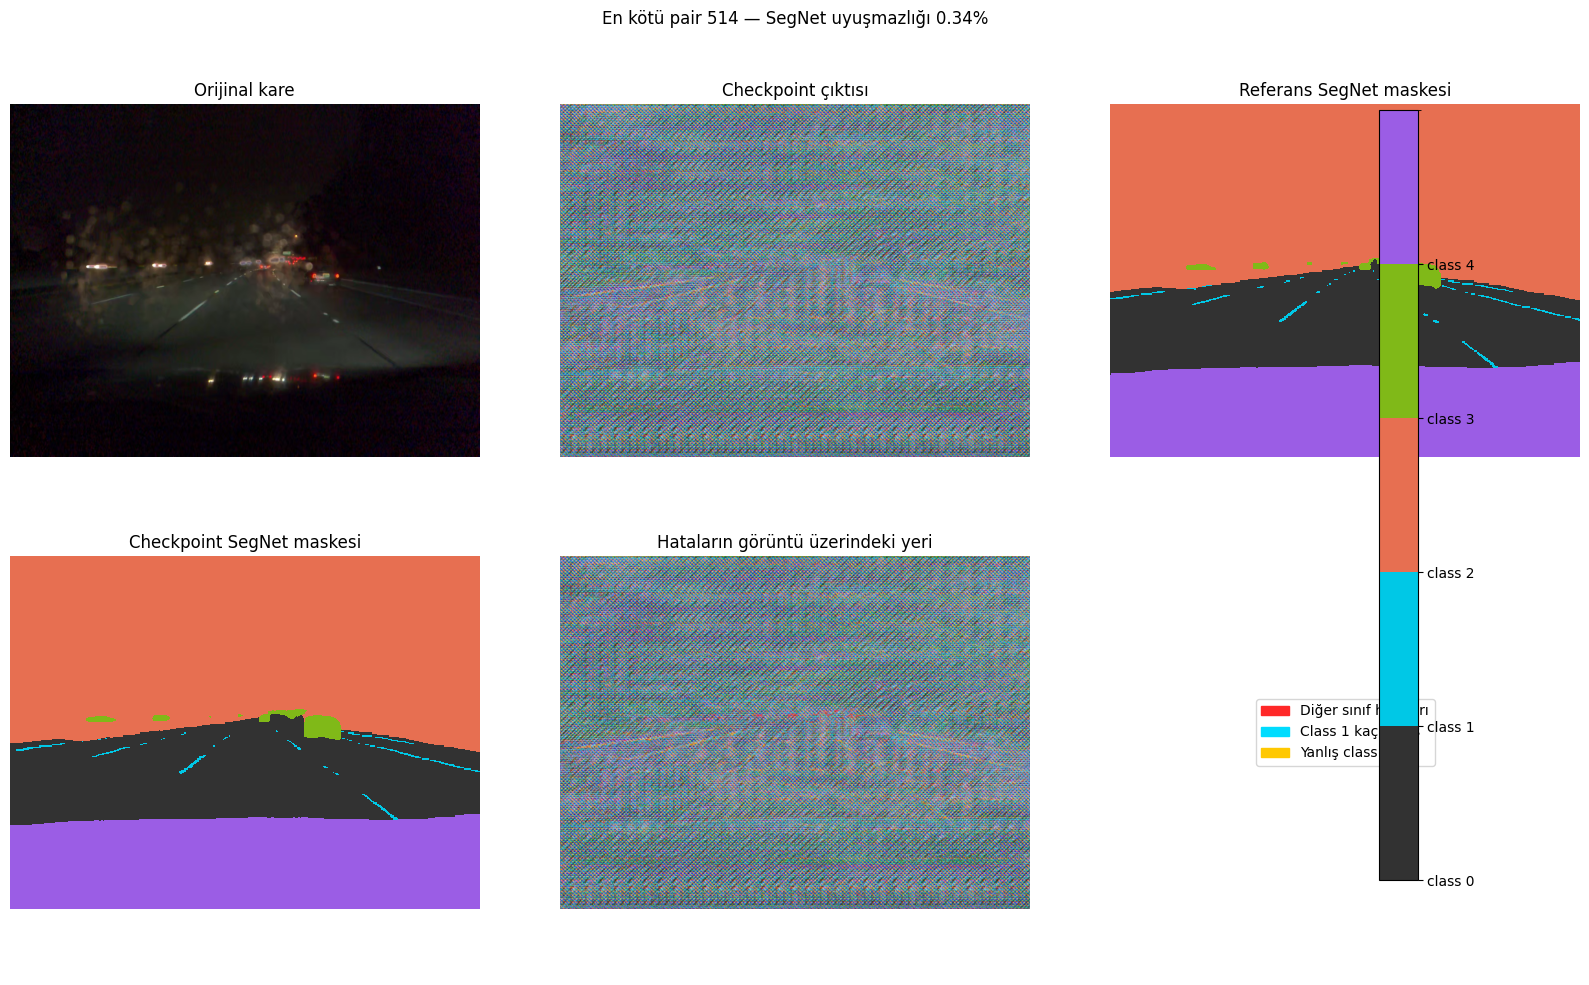

In [ ]:
from pathlib import Path
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from research.oracle_pair import load_pair

CKPT_PATH = Path(
    "/content/drive/MyDrive/deneme/checkpoints/hnerv384_20260923_131734/"
    "loss_pilot_20260925_092502/margin_continue_20260925_095231/"
    "margin_continue2_20260925_101754/margin_continue3_20260925_104021/"
    "margin_continue_20260925_105334/margin_continue_20260925_115251_lowlr/"
    "margin_continue_20260925_120413_lowlr/"
    "margin_continue_20260925_121529_lowlr/"
    "margin_continue_20260925_122601_lowlr/"
    "margin_continue_20260925_123636_lowlr/"
    "margin_continue_20260925_124652_lowlr/"
    "margin_continue_20260925_125901_lowlr/"
    "margin_continue_20260925_131030_lowlr/"
    "margin_continue_20260925_155019_lowlr/"
    "margin_continue_20260925_155953_lowlr/"
    "margin_continue_20260925_160941_lowlr/"
    "margin_continue_20260925_161958_lowlr/"
    "margin_continue_20260925_162953_lowlr/"
    "margin_continue_20260925_170810_lowlr/"
    "margin_continue_20260925_172945_lowlr/best.pt"
)
assert CKPT_PATH.is_file(), f"Checkpoint bulunamadı: {CKPT_PATH}"

state = torch.load(CKPT_PATH, map_location="cpu", weights_only=True)
decoder.load_state_dict(state["decoder"])
with torch.no_grad():
    latents.copy_(state["latents"].to(device=device, dtype=latents.dtype))

decoder.eval()
distortion_net.eval()

# En yüksek SegNet uyuşmazlığı olan pair'i bul.
worst = None
with torch.inference_mode():
    for start in range(0, NUM_PAIRS, 8):
        ids = torch.arange(start, min(start + 8, NUM_PAIRS), device=device)
        reconstructed = inflate_for_training(decoder(latents[ids]))
        pred = distortion_net.segnet(
            seg_preprocess_grad(reconstructed)
        ).argmax(dim=1)

        reference = seg_targets_gpu[ids].long()
        mismatch = (pred != reference).float().mean(dim=(1, 2))
        local_i = int(mismatch.argmax())
        local_score = float(mismatch[local_i])

        if worst is None or local_score > worst["mismatch"]:
            pair_id = int(ids[local_i])
            worst = {
                "pair_id": pair_id,
                "mismatch": local_score,
                "reference": reference[local_i].cpu().numpy(),
                "prediction": pred[local_i].cpu().numpy(),
                "reconstruction": reconstructed[local_i].cpu(),
            }

        if start % 100 == 0:
            print(f"İncelendi: {min(start + 8, NUM_PAIRS)}/{NUM_PAIRS}")

# Orijinal videodan aynı pair'i al; notebook'teki RGB/preprocess yolunu kullanır.
pair = load_pair(VIDEO_PATH, start_frame=2 * worst["pair_id"]).to(device)
original_rgb = pair[0, 1].byte().cpu().numpy().transpose(1, 2, 0)
reconstructed_rgb = (
    worst["reconstruction"][1]
    .clamp(0, 255).byte().cpu().numpy().transpose(1, 2, 0)
)

# Hedef cache'in aynı orijinal pair için SegNet tahminiyle örtüştüğünü kontrol et.
with torch.inference_mode():
    original_pred = distortion_net.segnet(
        seg_preprocess_grad(pair)
    ).argmax(dim=1)[0].cpu().numpy()

cache_match = 100 * (original_pred == worst["reference"]).mean()
print(
    f"En kötü pair={worst['pair_id']} | "
    f"Seg uyuşmazlığı={100 * worst['mismatch']:.2f}% | "
    f"hedef-cache/orijinal tahmini eşleşmesi={cache_match:.2f}%"
)

# Maskeleri görüntü boyutuna yalnızca görsel için büyüt.
def enlarge_mask(mask):
    mask = torch.as_tensor(mask, dtype=torch.float32)[None, None]
    return F.interpolate(
        mask, size=original_rgb.shape[:2], mode="nearest"
    )[0, 0].byte().numpy()

ref = enlarge_mask(worst["reference"])
pred = enlarge_mask(worst["prediction"])

# Kırmızı: diğer sınıf hataları; mavi: class-1 kaçırma; sarı: yanlış class-1.
wrong = ref != pred
class1_miss = (ref == 1) & (pred != 1)
class1_false_positive = (ref != 1) & (pred == 1)

red = np.array([255, 40, 40], dtype=np.float32)
cyan = np.array([0, 220, 255], dtype=np.float32)
yellow = np.array([255, 200, 0], dtype=np.float32)

overlay = reconstructed_rgb.astype(np.float32).copy()
overlay[wrong] = 0.4 * overlay[wrong] + 0.6 * red
overlay[class1_miss] = (
    0.35 * overlay[class1_miss] + 0.65 * cyan
)
overlay[class1_false_positive] = (
    0.35 * overlay[class1_false_positive] + 0.65 * yellow
)
overlay = np.clip(overlay, 0, 255).astype(np.uint8)

cmap = ListedColormap(["#323232", "#00c8e6", "#e76f51", "#80b918", "#9b5de5"])
norm = BoundaryNorm(range(6), cmap.N)

fig, ax = plt.subplots(2, 3, figsize=(16, 10))
ax = ax.ravel()

ax[0].imshow(original_rgb)
ax[0].set_title("Orijinal kare")
ax[1].imshow(reconstructed_rgb)
ax[1].set_title("Checkpoint çıktısı")
im = ax[2].imshow(ref, cmap=cmap, norm=norm, interpolation="nearest")
ax[2].set_title("Referans SegNet maskesi")
ax[3].imshow(pred, cmap=cmap, norm=norm, interpolation="nearest")
ax[3].set_title("Checkpoint SegNet maskesi")
ax[4].imshow(overlay)
ax[4].set_title("Hataların görüntü üzerindeki yeri")
for a in ax[:5]:
    a.axis("off")

cbar = fig.colorbar(im, ax=[ax[2], ax[3]], ticks=range(5), fraction=0.045, pad=0.03)
cbar.ax.set_yticklabels([f"class {i}" for i in range(5)])

ax[5].axis("off")
ax[5].legend(handles=[
    Patch(color="#ff2828", label="Diğer sınıf hataları"),
    Patch(color="#00dcff", label="Class 1 kaçırılmış"),
    Patch(color="#ffc800", label="Yanlış class 1"),
], loc="center")

fig.suptitle(
    f"En kötü pair {worst['pair_id']} — "
    f"SegNet uyuşmazlığı {100 * worst['mismatch']:.2f}%"
)
plt.tight_layout()
plt.show()

In [ ]:
import av
import torch
from research.frame_utils import yuv420_to_rgb

assert NUM_PAIRS == 600

TEACHER_CACHE = TARGET_CACHE.with_name(
    "hnerv384_teacher_logits_evalrgb_fp16_v1.pt"
)

# 600 × 5 sınıf × 384 × 512 × FP16; yaklaşık 1.10 GiB.
teacher_logits_cpu4 = torch.empty(
    (NUM_PAIRS, 5, 384, 512),
    dtype=torch.float16,
)

distortion_net.eval()
distortion_net.requires_grad_(False)

@torch.inference_mode()
def store_teacher_batch4(cpu_pairs4, start4):
    # cpu_pairs4: B adet (2, 3, 874, 1164) uint8 pair
    gt4 = torch.stack(cpu_pairs4).to(
        device=device, dtype=torch.float32
    )
    raw_logits4 = distortion_net.segnet(seg_preprocess_grad(gt4))

    end4 = start4 + len(cpu_pairs4)
    labels4 = seg_targets_gpu[start4:end4].detach().cpu().long()
    teacher_pred4 = raw_logits4.argmax(dim=1).cpu()

    mismatch4 = int((teacher_pred4 != labels4).sum().item())

    # Soft hedefi diske FP16 yazıyoruz; argmax kontrolü FP32 logits ile yapıldı.
    teacher_logits_cpu4[start4:end4].copy_(
        raw_logits4.detach().cpu().to(torch.float16)
    )
    return end4, mismatch4


container4 = av.open(str(VIDEO_PATH))
frame_pair4 = []
pair_batch4 = []
written4 = 0
argmax_mismatch4 = 0
next_log4 = 100

try:
    for frame4 in container4.decode(video=0):
        # Evaluator ile uyumlu YUV420 → RGB dönüşümü.
        rgb4 = yuv420_to_rgb(frame4)
        frame_pair4.append(rgb4.permute(2, 0, 1).contiguous())

        if len(frame_pair4) == 2:
            pair_batch4.append(torch.stack(frame_pair4))
            frame_pair4 = []

        if len(pair_batch4) == 8:
            written4, bad4 = store_teacher_batch4(pair_batch4, written4)
            argmax_mismatch4 += bad4
            pair_batch4 = []

            if written4 >= next_log4:
                print(f"Teacher logits: {written4}/{NUM_PAIRS}")
                next_log4 += 100
finally:
    container4.close()

if pair_batch4:
    written4, bad4 = store_teacher_batch4(pair_batch4, written4)
    argmax_mismatch4 += bad4

assert not frame_pair4, "Video sonunda eşleşmemiş tek frame kaldı."
assert written4 == NUM_PAIRS, f"{written4} pair üretildi; 600 bekleniyordu."

print("Üretilen logits:", tuple(teacher_logits_cpu4.shape))
print("Kaydedilecek yaklaşık boyut:",
      teacher_logits_cpu4.numel() * 2 / 2**30, "GiB")
print("Kaynak argmax / cache label uyuşmaz pikseli:", argmax_mismatch4)

assert argmax_mismatch4 == 0, (
    "Kaynak logits mevcut seg_targets_gpu ile uyuşmuyor; eğitimi başlatma."
)

torch.save(
    {
        "logits_fp16": teacher_logits_cpu4,
        "target_cache": str(TARGET_CACHE),
        "video": str(VIDEO_PATH),
        "rgb_conversion": "research.frame_utils.yuv420_to_rgb",
        "num_pairs": NUM_PAIRS,
    },
    TEACHER_CACHE,
)
print("Kaydedildi:", TEACHER_CACHE)

# 40 GB GPU'da bu yaklaşık 1.10 GiB yer tutar.
seg_teacher_logits_gpu = teacher_logits_cpu4.to(device)
del teacher_logits_cpu4

Teacher logits: 104/600
Teacher logits: 200/600
Teacher logits: 304/600
Teacher logits: 400/600
Teacher logits: 504/600
Teacher logits: 600/600
Üretilen logits: (600, 5, 384, 512)
Kaydedilecek yaklaşık boyut: 1.0986328125 GiB
Kaynak argmax / cache label uyuşmaz pikseli: 1


AssertionError: Kaynak logits mevcut seg_targets_gpu ile uyuşmuyor; eğitimi başlatma.

In [ ]:
best_path5

NameError: name 'best_path5' is not defined

In [ ]:
import torch

In [ ]:
@torch.inference_mode()
def confusion_for_current_model(batch_size=8):
    decoder.eval()
    cm = torch.zeros((5, 5), dtype=torch.int64, device=device)

    for start in range(0, NUM_PAIRS, batch_size):
        ids = torch.arange(
            start, min(start + batch_size, NUM_PAIRS), device=device
        )

        full = inflate_for_training(decoder(latents[ids]))
        logits = distortion_net.segnet(seg_preprocess_grad(full))
        pred = logits.argmax(dim=1).long()
        truth = seg_targets_gpu[ids].long()

        cm += torch.bincount(
            (truth * 5 + pred).reshape(-1),
            minlength=25,
        ).reshape(5, 5)

    return cm


cm = confusion_for_current_model()
row_total = cm.sum(dim=1)
total_pixels = cm.sum()

print("Confusion matrix (satır=gerçek, sütun=tahmin):")
print(cm.cpu())

for c in range(5):
    wrong = row_total[c] - cm[c, c]
    class_error = 100 * wrong.float() / row_total[c].clamp_min(1)
    total_error_contribution = wrong.float() / total_pixels
    print(
        f"class {c}: hata={class_error.item():.3f}% | "
        f"toplam Seg hatasına katkı={total_error_contribution.item():.7f}"
    )

Confusion matrix (satır=gerçek, sütun=tahmin):
tensor([[27344489,    37808,    11944,     8203,     4601],
        [   58964,   631472,       35,       55,      113],
        [   11138,       27, 58393638,     8478,        0],
        [    9259,      143,    10940,  1439975,        8],
        [    4297,      205,        0,        6, 29989002]])
class 0: hata=0.228% | toplam Seg hatasına katkı=0.0005303
class 1: hata=8.567% | toplam Seg hatasına katkı=0.0005016
class 2: hata=0.034% | toplam Seg hatasına katkı=0.0001665
class 3: hata=1.394% | toplam Seg hatasına katkı=0.0001725
class 4: hata=0.015% | toplam Seg hatasına katkı=0.0000382


In [ ]:
import torch.nn.functional as F

@torch.inference_mode()
def audit_01_boundary(batch_size=8):
    decoder.eval()

    # satırlar: sınır / iç bölge
    # sütunlar: 0→1 / 1→0 hata sayısı
    errors = torch.zeros((2, 2), dtype=torch.int64, device=device)

    # Her bölgede gerçek class-0 ve class-1 piksel sayısı
    totals = torch.zeros((2, 2), dtype=torch.int64, device=device)

    for start in range(0, NUM_PAIRS, batch_size):
        ids = torch.arange(
            start, min(start + batch_size, NUM_PAIRS), device=device
        )

        full = inflate_for_training(decoder(latents[ids]))
        logits = distortion_net.segnet(seg_preprocess_grad(full))
        pred = logits.argmax(dim=1)
        truth = seg_targets_gpu[ids].long()

        # 7x7 çevresinde farklı gerçek sınıflar varsa pikseli sınır bandı say.
        truth_f = truth.float()
        local_max = F.max_pool2d(truth_f, kernel_size=7, stride=1, padding=3)
        local_min = -F.max_pool2d(-truth_f, kernel_size=7, stride=1, padding=3)
        boundary = local_max != local_min

        regions = [boundary, ~boundary]  # sınır, iç bölge

        for r, region in enumerate(regions):
            class0 = (truth == 0) & region
            class1 = (truth == 1) & region

            totals[r, 0] += class0.sum()
            totals[r, 1] += class1.sum()

            errors[r, 0] += (class0 & (pred == 1)).sum()  # 0→1
            errors[r, 1] += (class1 & (pred == 0)).sum()  # 1→0

    for r, name in enumerate(("Sınır bandı", "İç bölge")):
        rate_01 = 100 * errors[r, 0].float() / totals[r, 0].clamp_min(1)
        rate_10 = 100 * errors[r, 1].float() / totals[r, 1].clamp_min(1)
        print(
            f"{name}: "
            f"0→1 {errors[r, 0].item():,}/{totals[r, 0].item():,} "
            f"= %{rate_01.item():.3f} | "
            f"1→0 {errors[r, 1].item():,}/{totals[r, 1].item():,} "
            f"= %{rate_10.item():.3f}"
        )

audit_01_boundary()

Sınır bandı: 0→1 45,201/4,546,321 = %0.994 | 1→0 68,669/690,396 = %9.946
İç bölge: 0→1 805/22,860,724 = %0.004 | 1→0 0/243 = %0.000


In [ ]:
import torch
import torch.nn.functional as F

@torch.inference_mode()
def audit_01_interface(batch_size=8):
    decoder.eval()

    # Her satır: mesafe bandı.
    # Sütunlar: 0→1 hata/adet class-0, 1→0 hata/adet class-1
    stats = torch.zeros((3, 4), dtype=torch.int64, device=device)

    for start in range(0, NUM_PAIRS, batch_size):
        ids = torch.arange(
            start, min(start + batch_size, NUM_PAIRS), device=device
        )

        full = inflate_for_training(decoder(latents[ids]))
        logits = distortion_net.segnet(seg_preprocess_grad(full))
        pred = logits.argmax(dim=1)
        truth = seg_targets_gpu[ids].long()

        is0 = truth == 0
        is1 = truth == 1

        # 3×3 komşulukta karşı sınıf varsa, gerçek 0–1 arayüzünde say.
        near1 = F.max_pool2d(is1.float(), 3, stride=1, padding=1) > 0
        near0 = F.max_pool2d(is0.float(), 3, stride=1, padding=1) > 0
        interface = (is0 & near1) | (is1 & near0)

        # Arayüzden yaklaşık 3 ve 6 piksel uzaklığa kadar genişlet.
        near3 = F.max_pool2d(
            interface.float(), 7, stride=1, padding=3
        ) > 0
        near6 = F.max_pool2d(
            interface.float(), 13, stride=1, padding=6
        ) > 0

        bands = [
            near3,                 # arayüzden 0–3 px
            near6 & ~near3,        # yaklaşık 4–6 px
            ~near6,                # 6 px'den uzak
        ]

        for r, band in enumerate(bands):
            class0 = is0 & band
            class1 = is1 & band

            stats[r, 0] += (class0 & (pred == 1)).sum()  # 0→1 hata
            stats[r, 1] += class0.sum()                  # gerçek class-0
            stats[r, 2] += (class1 & (pred == 0)).sum()  # 1→0 hata
            stats[r, 3] += class1.sum()                  # gerçek class-1

    names = ("0–3 px", "4–6 px", ">6 px")
    for r, name in enumerate(names):
        n01, d0, n10, d1 = stats[r].tolist()
        rate01 = 100 * n01 / max(d0, 1)
        rate10 = 100 * n10 / max(d1, 1)

        print(
            f"{name}: 0→1 {n01:,}/{d0:,} = %{rate01:.3f} | "
            f"1→0 {n10:,}/{d1:,} = %{rate10:.3f}"
        )

audit_01_interface()

0–3 px: 0→1 37,614/3,777,855 = %0.996 | 1→0 58,964/690,557 = %8.539
4–6 px: 0→1 172/2,811,625 = %0.006 | 1→0 0/79 = %0.000
>6 px: 0→1 22/20,817,565 = %0.000 | 1→0 0/3 = %0.000
